# Example 8.2: Clipping and noise floor

An accelerometer and its acquisition system have a finite measurement range and introduce measurement noise. Large accelerations may be **clipped**, while small vibration components may be hidden by the **noise floor**. Both effects influence our measurements.



In [7]:
import numpy as np
from matplotlib import pyplot as plt

fs = 1000.0                       # Sampling frequency (Hz)
T = 60.0                          # Record duration (s)
t = np.arange(round(T * fs)) / fs


## Clipping when signal exeeds measurement range

Consider a sinusoidal acceleration with an amplitude that rises and later falls back down. The sensor can only measure between $\pm2g$, so it records:

$$a_c(t)=\mathrm{clip}\big(a(t),-a_{\max},a_{\max}\big),\qquad a_{\max}=2g=19.62\ \mathrm{m/s^2}.$$

Since the signal is distorted, the FFT is also distorted: we see that false peaks appear.


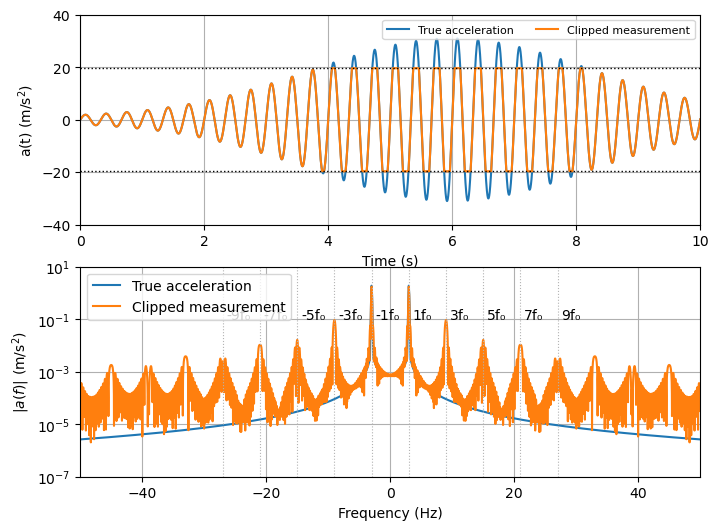

In [8]:
# Measurement range
g=9.81
clip_limit = 2*g   # Try 1g, 2g, 3g, 4g

# Create signal
A_t = 1 + 30*np.exp(-0.1*(t-6)**2)
f0 = 3.0
a = A_t * np.sin(2 * np.pi * f0 * t)
a_clip = np.clip(a, -clip_limit, clip_limit)

# Take FFT
N = len(a)
a_fft = np.fft.fftshift(1/N * np.fft.fft(a))
a_clip_fft = np.fft.fftshift(1/N * np.fft.fft(a_clip))
f = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))

fig, axs = plt.subplots(2, 1, figsize=(8, 6))

# Plot time series
axs[0].plot(t, a, label='True acceleration')
axs[0].plot(t, a_clip, label='Clipped measurement')

for limit in [-clip_limit, clip_limit]:
    axs[0].axhline(limit, color='k', linestyle=':', linewidth=1)
axs[0].set(xlim=(0, 10), ylim=(-40, 40), xlabel='Time (s)', ylabel=r'a(t) (m/s$^2$)')
axs[0].legend(loc='upper right', fontsize=8, ncol=3)
axs[0].grid(True)


# Plot frequency domain
axs[1].semilogy(f, np.abs(a_fft), label='True acceleration')
axs[1].semilogy(f, np.abs(a_clip_fft), label='Clipped measurement')
for order in [-9, -7, -5, -3, -1, 1, 3, 5, 7, 9]:
    axs[1].axvline(order * f0, color='0.7', linestyle=':', linewidth=0.8)
    axs[1].text(order * f0 + 0.6, 0.1, f'{order}f₀', fontsize=10)
axs[1].set(xlim=(-50, 50), ylim=(1e-7, 10), xlabel='Frequency (Hz)',ylabel=r'$|a(f)|$ (m/s$^2$)')
axs[1].legend()
axs[1].grid(True)


## Noise floor

Let the signal consist of two harmonic components:

$$a(t)=A_1 \sin(2\pi f_1 t)+A_2 \sin(2\pi f_2 t)$$

We now introduce measurement noise, so the measured acceleration is $$a_{meas}[n]=a[n]+\eta[n]$$

The noise $\eta[n]$ is zero-mean Gaussian white noise with standard deviation $\sigma_\eta$. Increasing the noise raises the background FFT magnitudesand makes the smaller signal component difficult to distinguish. 


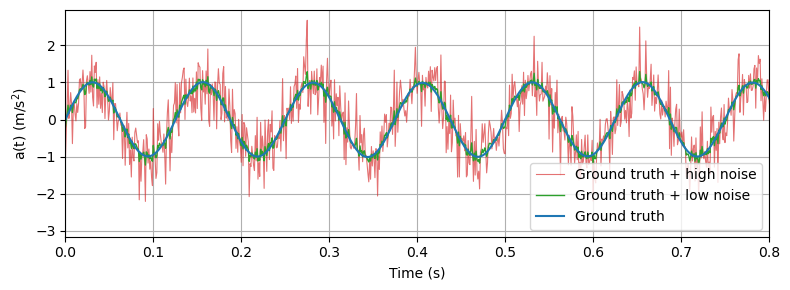

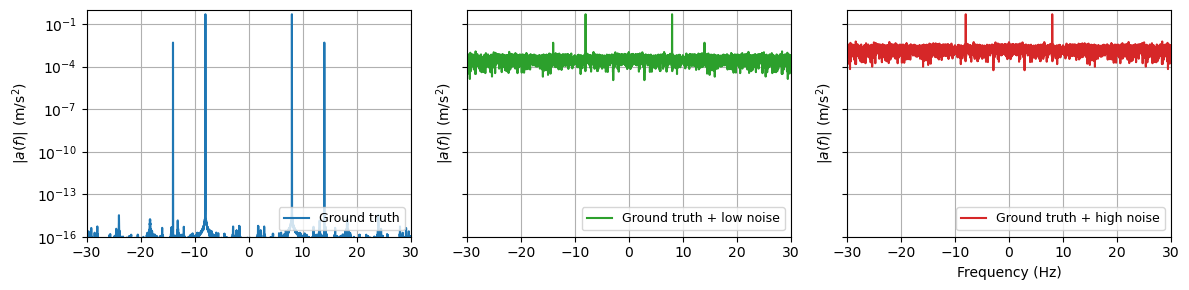

In [9]:
f1 = 8.0
A1 = 1

f2 = 14.0
A2 = 0.01

a_true = A1*np.sin(2 * np.pi * f1 * t) +A2*np.sin(2 * np.pi * f2 * t)  # Constant amplitude for the noise example

sigma_low, sigma_high = 0.1, 0.5  # Noise RMS (m/s²)

unit_noise = np.random.randn(len(t))
y_low = a_true + sigma_low * unit_noise
y_high = a_true + sigma_high * unit_noise

# Normalize each FFT by the number of samples
N = len(a_true)
a_true_fft = np.fft.fftshift(1/N * np.fft.fft(a_true))
y_low_fft = np.fft.fftshift(1/N * np.fft.fft(y_low))
y_high_fft = np.fft.fftshift(1/N * np.fft.fft(y_high))
f = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))

# Time series
plt.figure(figsize=(8, 3))
plt.plot(t, y_high, color='C3', alpha=0.65, linewidth=0.8, label='Ground truth + high noise')
plt.plot(t, y_low, color='C2', linewidth=1, label='Ground truth + low noise')
plt.plot(t, a_true, color='C0', linewidth=1.5, label='Ground truth')
plt.xlim(0, 0.8)
plt.xlabel('Time (s)')
plt.ylabel(r'a(t) (m/s$^2$)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

# Separate FFT subplots with identical axes for comparison
fig, axs = plt.subplots(1, 3, figsize=(12, 3), sharex=True, sharey=True)
axs[0].semilogy(f, np.abs(a_true_fft), color='C0', label='Ground truth')
axs[1].semilogy(f, np.abs(y_low_fft), color='C2', label='Ground truth + low noise')
axs[2].semilogy(f, np.abs(y_high_fft), color='C3', label='Ground truth + high noise')
for ax in axs:
    ax.set(xlim=(-30, 30), ylim=(1e-16, 1), ylabel=r'$|a(f)|$ (m/s$^2$)')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True)
axs[2].set_xlabel('Frequency (Hz)')
plt.tight_layout()
plt.show()


The flat noise level visible in these frequency domain plots is called *noise floor*. This floor appears as constant across all frequencies since it originates from white noise (which has a constant spectrum).


## Signal-to-noise ratio (SNR)

The SNR compares the mean-square signal with the mean-square noise:

$$\mathrm{SNR}=\frac{a_{\mathrm{rms}}^2}{\sigma_\eta^2}$$

We generally want the $\mathrm{SNR} >> 1$. The SNRs use the noise over the *entire sampled frequency band*, not just the frequencies displayed in the plot. A good overall SNR does not guarantee that the weak component is visible. Conversely, a sinusoid with a negative broadband SNR can still be visible in the FFT because its contribution is concentrated in a few bins while the noise is spread across many bins. Its visibility therefore also depends on record length and frequency resolution.
